# 03 — Moduladores: Mach-Zehnder e modulador em quadratura

Este notebook segue a aula (`docs/04-class/context.md`) e o guia `docs/moduladores.md`.
A aula diz que os moduladores "podem ser descritos por monocromático, pois se usam ondas
contínuas": a entrada óptica é o laser CW do notebook 02 (modelo B, `CWLaser`), e o sinal
vem de um modulador externo.

Regras usadas em todas as figuras (as mesmas dos notebooks 01 e 02):

- a física simulada vem **sempre** do pacote (`simcopy.kernels.modulator`); o notebook só
  escreve as formas fechadas, que são a referência;
- forma fechada (linha) e simulação (pontos) juntas, e o erro em painel próprio;
- as asserções numéricas ficam nos testes do pytest, escritos pelo grupo (issue #15).

Fontes: Agrawal, *Sistemas de Comunicação por Fibra Óptica*, 4ª ed., seções 3.4.2 e 10.1.2
(citado pelo número da equação), e o código do professor (`legacy/draft.py`, `MZM` e
`DPQAM_transmitter`). O texto separa **fato** (com a fonte) de **dedução**.

**Ainda não há blocos de modulador** (`ExternalModulator`, `IQModulator`): a configuração
depende das dúvidas M1–M9 do guia. Aqui só o kernel, que é física do Agrawal.

## 0. Equações

**[Fato: Agrawal, Eq. 10.1.2–10.1.4]** No braço j do Mach-Zehnder (MZ) de LiNbO₃ a fase é
$\phi_j = \pi V_j/V_\pi$. O campo é dividido ao meio e recombinado:

$$A_t = \tfrac{1}{2}A_i\left(e^{i\phi_1} + e^{i\phi_2}\right),\qquad
t_m = \cos\!\left[\tfrac{1}{2}(\phi_1 - \phi_2)\right]\exp\!\left[\tfrac{i}{2}(\phi_1 + \phi_2)\right]$$

**[Fato: Agrawal, Eq. 10.1.5]** Em push-pull ($V_2 = -V_1 + V_b$) a soma das fases é
constante e o MZ só modula a amplitude:
$T_m = |t_m|^2 = \cos^2\!\left[\pi(2V_1 - V_b)/(2V_\pi)\right]$. Com a mesma tensão nos dois
braços ele só modula a fase.

**[Fato: Agrawal, Fig. 10.3]** Modulador em quadratura: dois MZ em push-pull, um em cada
braço de um MZ externo, com π/2 entre os braços. Saída $\tfrac{1}{2}[t(V_I) + e^{i\theta}t(V_Q)]$,
θ = π/2 no ideal.

O kernel usa a polarização simétrica do professor, $(v - V_b/2,\,-v + V_b/2)$, que só difere
da forma do Agrawal por uma fase constante. $V_\pi$ = 5 V, como no VPI.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from simcopy.kernels.modulator.mzm import mzm_field, push_pull, iq_field
from simcopy.components.tx.laser import CWLaser
from simcopy.config.system import CWLaserConfig
from simcopy.core.context import SimContext
from simcopy.core.grid import TimeGrid
from simcopy.core.signals import Domain, SignalGeometry, Waveform
from simcopy.core.units import C_LIGHT

plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "axes.grid": True,
                     "grid.alpha": 0.3, "legend.fontsize": 7.5})
C3 = ["tab:blue", "tab:orange", "tab:green"]
VPI = 5.0
F_LASER = C_LIGHT / 1550e-9
ARMS_PROF = (0.5 * 10 ** (-2 / 20), 0.5 * 10 ** (-3 / 20))   # perdas de braço do professor

def pp(v, v_bias, a=(0.5, 0.5)):
    """Transmissão de campo do MZM em push-pull (kernel)."""
    return mzm_field(1.0, *push_pull(v, v_bias), VPI, *a)

def eletrico(x, sps, canal=0, fs=1e12):
    """Waveform elétrico (1, N) com x(t) real, grade de 1 ps."""
    x = np.asarray(x, dtype=complex)[None, :]
    return Waveform(samples=x, grid=TimeGrid(fs, x.shape[1]), domain=Domain.ELECTRICAL,
                    geometry=SignalGeometry(n_symbols=x.shape[1] // sps, bits_per_symbol=1,
                                            samples_per_symbol=sps, n_pol=1),
                    channel_id=canal)

def nrz(simbolos, sps, borda=30):
    """Sinal NRZ sintético com bordas por média móvel (ainda não há formatador de pulso)."""
    return np.convolve(np.repeat(np.asarray(simbolos, float), sps), np.ones(borda) / borda, "same")

## 1. Função de transferência e pontos de polarização

Em push-pull, a Eq. 10.1.5 dá a curva de transmissão em função da tensão. A tensão de
polarização $V_b$ escolhe o ponto de operação:

- $V_b = 0$: máximo da transmissão;
- $V_b = V_\pi/2$: **quadratura**, $T = 1/2$ em $V = 0$; a transmissão varia
  aproximadamente de forma linear em torno desse ponto: é o ponto do OOK;
- $V_b = V_\pi$: **nulo**, $T = 0$ em $V = 0$; o campo é $\sin(\pi V/V_\pi)$, bipolar: é o ponto
  do BPSK e de cada braço do QAM. **[Dedução]** Pela Eq. 10.1.4 com $\phi_1 + \phi_2 = 0$.

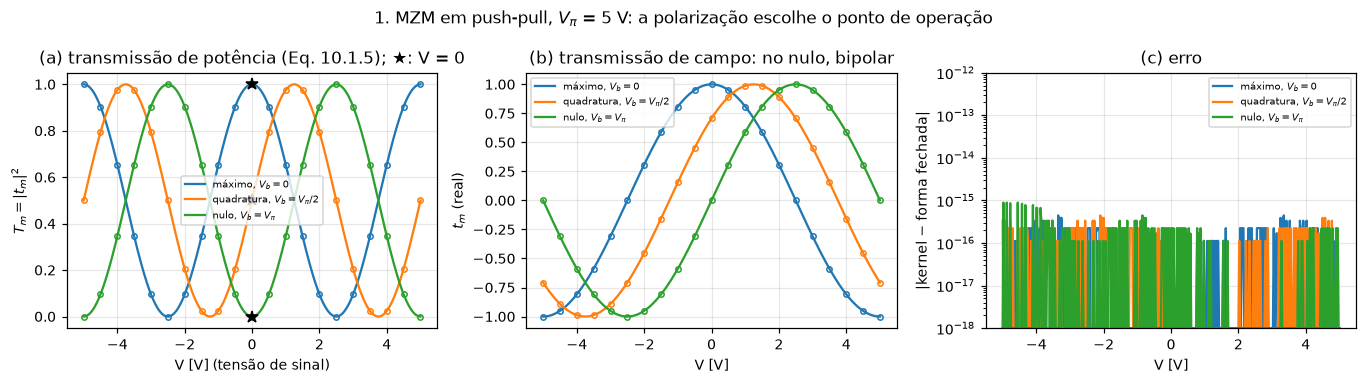

In [2]:
v = np.linspace(-VPI, VPI, 401)
pol = {"máximo, $V_b = 0$": 0.0, r"quadratura, $V_b = V_\pi/2$": VPI / 2, r"nulo, $V_b = V_\pi$": VPI}
fig, ax = plt.subplots(1, 3, figsize=(12.5, 3.5))
for i, (nome, vb) in enumerate(pol.items()):
    t = pp(v, vb)
    ana = np.cos(np.pi * (2 * v - vb) / (2 * VPI))
    ax[0].plot(v, ana ** 2, "-", color=C3[i], label=nome)
    ax[0].plot(v[::20], np.abs(t[::20]) ** 2, "o", ms=3.5, mfc="none", color=C3[i])
    ax[0].plot(0, np.abs(pp(0.0, vb)) ** 2, "k*", ms=8)
    ax[1].plot(v, ana, "-", color=C3[i], label=nome)
    ax[1].plot(v[::20], t.real[::20], "o", ms=3.5, mfc="none", color=C3[i])
    ax[2].semilogy(v, np.abs(t - ana) + 1e-18, "-", color=C3[i], label=nome)
ax[0].set(xlabel="V [V] (tensão de sinal)", ylabel="$T_m = |t_m|^2$",
          title="(a) transmissão de potência (Eq. 10.1.5); ★: V = 0")
ax[1].set(xlabel="V [V]", ylabel="$t_m$ (real)", title="(b) transmissão de campo: no nulo, bipolar")
ax[2].set(ylim=(1e-18, 1e-12), xlabel="V [V]", ylabel="|kernel − forma fechada|", title="(c) erro")
for a_ in ax: a_.legend(fontsize=6.5)
fig.suptitle(r"1. MZM em push-pull, $V_\pi$ = 5 V: a polarização escolhe o ponto de operação")
fig.tight_layout()

**Leitura.** As três curvas são a mesma cos², deslocada pela polarização. Um período inteiro
ocupa $2V_\pi$ de tensão de sinal no push-pull, porque cada braço recebe $\pm V$. No nulo, a
transmissão de campo (b) troca de sinal em V = 0: a fase óptica salta de π, o que é a
modulação BPSK. Em (a), entre o máximo e o nulo bastam $V_\pi/2$ de sinal em cada braço.

Testes: issue #15.

## 2. Chirp: push-pull × um braço só

**[Fato: Agrawal, texto após a Eq. 10.1.4]** Um MZ afeta a amplitude e a fase; só em
push-pull a soma das fases é constante e a fase de saída não varia (sem chirp).

**[Dedução, da Eq. 10.1.4]** Acionando só o braço 1 ($V_1 = v_s$, $V_2 = V_0$ fixo), a fase de
saída é $(\phi_1 + \phi_2)/2 = \pi(v_s + V_0)/(2V_\pi)$: varia com o sinal. Para a mesma
transmissão do push-pull é preciso o dobro da excursão num braço só: aqui
$v_s = 2v - V_\pi/4$ e $V_0 = V_\pi/4$, que dão a mesma diferença de fase
$\phi_1 - \phi_2 = \pi(2v - V_\pi/2)/V_\pi$ da quadratura em push-pull.

Abaixo, uma borda de subida e uma de descida, em quadratura, com sinal $\pm a$,
$a = 0{,}2\,V_\pi$: a transmissão vai de 0,024 a 0,976. (Com $a = V_\pi/4$ o bit 0 cairia no
nulo, onde o campo é zero e a fase não existe.)

excursão de fase com um braço: 1.2566 rad (Eq. 10.1.4: 2πa/V_π = 1.2566) | push-pull: 0.0e+00 rad


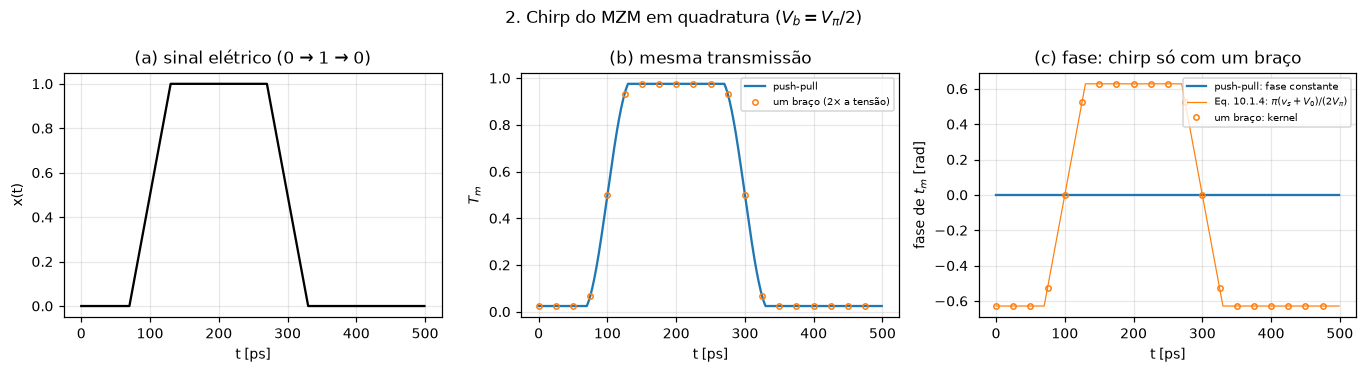

In [3]:
x2 = nrz([0, 1, 1, 0, 0], 100, borda=60)
t2 = np.arange(x2.size) * 1e-12
A2 = 0.2 * VPI
v2 = A2 * (2 * x2 - 1)                               # push-pull: sinal ±a em cada braço
t_pp = pp(v2, VPI / 2)
t_um = mzm_field(1.0, 2 * v2 - VPI / 4, VPI / 4, VPI)  # um braço: v_s = 2v - V_π/4, V_0 = V_π/4
fase_um = np.pi * ((2 * v2 - VPI / 4) + VPI / 4) / (2 * VPI)  # π(v_s + V_0)/(2V_π)
fig, ax = plt.subplots(1, 3, figsize=(12.5, 3.4))
ax[0].plot(t2 * 1e12, x2, "k-")
ax[0].set(xlabel="t [ps]", ylabel="x(t)", title="(a) sinal elétrico (0 → 1 → 0)")
ax[1].plot(t2 * 1e12, np.abs(t_pp) ** 2, "-", color=C3[0], label="push-pull")
ax[1].plot(t2[::25] * 1e12, np.abs(t_um[::25]) ** 2, "o", ms=3.5, mfc="none", color=C3[1],
           label="um braço (2× a tensão)")
ax[1].set(xlabel="t [ps]", ylabel="$T_m$", title="(b) mesma transmissão")
ax[2].plot(t2 * 1e12, np.angle(t_pp), "-", color=C3[0], label="push-pull: fase constante")
ax[2].plot(t2 * 1e12, fase_um, "-", color=C3[1], lw=0.8, label=r"Eq. 10.1.4: $\pi(v_s + V_0)/(2V_\pi)$")
ax[2].plot(t2[::25] * 1e12, np.angle(t_um[::25]), "o", ms=3.5, mfc="none", color=C3[1],
           label="um braço: kernel")
ax[2].set(xlabel="t [ps]", ylabel="fase de $t_m$ [rad]", title="(c) fase: chirp só com um braço")
for a_ in ax[1:]: a_.legend(fontsize=6.5)
fig.suptitle("2. Chirp do MZM em quadratura ($V_b = V_\\pi/2$)")
fig.tight_layout()
print(f"excursão de fase com um braço: {np.ptp(np.angle(t_um)):.4f} rad "
      f"(Eq. 10.1.4: 2πa/V_π = {2 * np.pi * A2 / VPI:.4f}) | push-pull: {np.ptp(np.angle(t_pp)):.1e} rad")

**Leitura.** As duas montagens dão a mesma potência (b), mas só o push-pull mantém a fase
(c). Com um braço só a fase acompanha o sinal e varia de $2\pi a/V_\pi$ = 1,26 rad entre os
bits 0 e 1 (saída da célula): a derivada
dessa fase é um chirp que a dispersão da fibra transforma em distorção, o mesmo problema da
modulação direta (notebook 02), em menor escala. É por isso que os transmissores usam
push-pull.

Testes: issue #15.

## 3. Extinção finita: braços desbalanceados

O Agrawal não modela extinção finita. O código do professor a obtém com perdas diferentes
nos dois braços (2 dB e 3 dB no padrão). **[Dedução, da Eq. 10.1.3 com amplitudes
$a_1 \ne a_2$]** O nulo deixa de ser zero:

$$T_{max} = (a_1 + a_2)^2,\quad T_{min} = (a_1 - a_2)^2,\quad
\frac{P_1}{P_0} = \left(\frac{a_1 + a_2}{a_1 - a_2}\right)^2$$

(o Agrawal define $r_{ex} = P_0/P_1$, Eq. 4.7.1; aqui em dB, $10\log_{10}(P_1/P_0)$). Com
$a_j = \tfrac{1}{2}10^{-IL_j/20}$, 2 e 3 dB dão 24,8 dB. O campo também deixa de ser real perto
do nulo: o desbalanço traz chirp residual.

extinção: dedução 24.8065 dB | kernel numa grade de 401 tensões 24.8065 dB


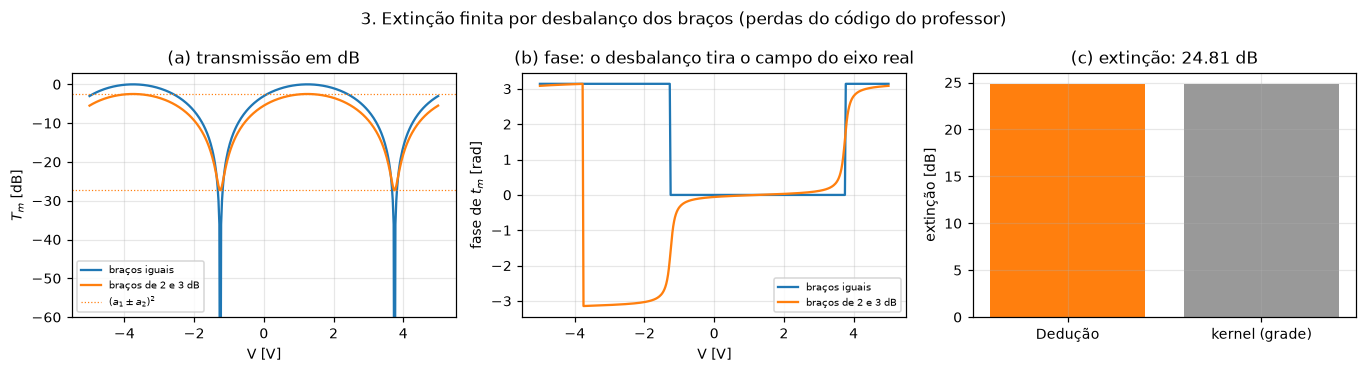

In [4]:
a1, a2 = ARMS_PROF
er_ana = 10 * np.log10(((a1 + a2) / (a1 - a2)) ** 2)
t_id, t_db = pp(v, VPI / 2), pp(v, VPI / 2, ARMS_PROF)
fig, ax = plt.subplots(1, 3, figsize=(12.5, 3.4))
ax[0].plot(v, 10 * np.log10(np.abs(t_id) ** 2 + 1e-12), "-", color=C3[0], label="braços iguais")
ax[0].plot(v, 10 * np.log10(np.abs(t_db) ** 2), "-", color=C3[1], label="braços de 2 e 3 dB")
ax[0].axhline(10 * np.log10((a1 + a2) ** 2), color=C3[1], ls=":", lw=0.8)
ax[0].axhline(10 * np.log10((a1 - a2) ** 2), color=C3[1], ls=":", lw=0.8,
              label="$(a_1 \\pm a_2)^2$")
ax[0].set(ylim=(-60, 3), xlabel="V [V]", ylabel="$T_m$ [dB]", title="(a) transmissão em dB")
ax[1].plot(v, np.angle(t_id * np.exp(-1j * np.angle(t_id[200]))), "-", color=C3[0], label="braços iguais")
ax[1].plot(v, np.angle(t_db), "-", color=C3[1], label="braços de 2 e 3 dB")
ax[1].set(xlabel="V [V]", ylabel="fase de $t_m$ [rad]", title="(b) fase: o desbalanço tira o campo do eixo real")
er_med = 10 * np.log10(np.max(np.abs(t_db) ** 2) / np.min(np.abs(t_db) ** 2))
ax[2].bar([0, 1], [er_ana, er_med], color=[C3[1], "0.6"], tick_label=["Dedução", "kernel (grade)"])
ax[2].set(ylabel="extinção [dB]", title=f"(c) extinção: {er_ana:.2f} dB")
for a_ in ax[:2]: a_.legend(fontsize=6.5)
fig.suptitle("3. Extinção finita por desbalanço dos braços (perdas do código do professor)")
fig.tight_layout()
print(f"extinção: dedução {er_ana:.4f} dB | kernel numa grade de 401 tensões {er_med:.4f} dB")

**Leitura.** Com braços iguais o nulo vai a zero (limitado só pelo eixo do gráfico); com
braços de 2 e 3 dB a transmissão não desce de −27,3 dB, 24,8 dB abaixo do máximo de −2,5 dB.
Em (c) a extinção medida no kernel coincide com a dedução porque a grade de tensões passa
pelo máximo e pelo nulo ($\pm V_\pi/4$). Em (b) a fase com braços iguais só salta de π no nulo; com braços
desbalanceados ela gira continuamente perto dele. O VPI usa 30 dB (dúvida M4 do guia: como
mapear a extinção e a perda de inserção em amplitudes de braço).

Testes: issue #15.

## 4. OOK com o laser CW

A cadeia IMDD externa da aula: laser CW → MZM em quadratura. A portadora sai do bloco
`CWLaser` (1 mW, 500 kHz, como no VPI) e o MZM multiplica o campo pela transmissão. O sinal
elétrico é OOK sintético a 10 Gb/s.

**[Dedução, da Eq. 10.1.5]** Em quadratura, com sinal $\pm a$ em cada braço, a extinção é
$T(+a)/T(-a) = \cos^2(\pi a/V_\pi - \pi/4)/\cos^2(\pi a/V_\pi + \pi/4)$: infinita em
$a = V_\pi/4$ (excursão completa) e menor com sinal menor.

extinção medida (dB): [ 2.775  5.857  9.764 16.006 30.054] | dedução: [ 2.775  5.857  9.764 16.006 30.054]
braços de 2 e 3 dB com a = V_π/4: 24.81 dB


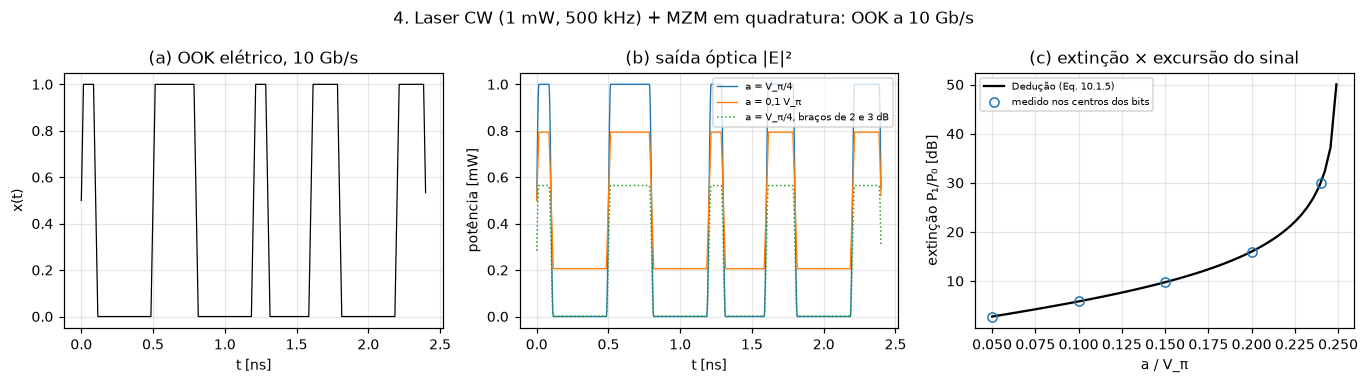

In [5]:
SPS = 100
bits4 = np.random.default_rng(3).integers(0, 2, 24)
x4 = nrz(bits4, SPS)
xe = eletrico(x4, SPS)
ctx = SimContext(grid=xe.grid, root_seed=1)
portadora = CWLaser(CWLaserConfig(power=1e-3, linewidth=500e3), F_LASER)(xe, ctx).samples[0]
t4 = xe.grid.time

def ook(a, bracos=(0.5, 0.5)):
    return portadora * pp(a * (2 * x4 - 1), VPI / 2, bracos)

centros = np.arange(bits4.size) * SPS + SPS // 2
def extincao(campo):
    p = np.abs(campo[centros]) ** 2
    return 10 * np.log10(p[bits4 == 1].mean() / p[bits4 == 0].mean())

a_eixo = np.linspace(0.05, 0.249, 60) * VPI
er_curva = 10 * np.log10(np.cos(np.pi * a_eixo / VPI - np.pi / 4) ** 2
                         / np.cos(np.pi * a_eixo / VPI + np.pi / 4) ** 2)
a_med = np.array([0.05, 0.1, 0.15, 0.2, 0.24]) * VPI
er_med4 = [extincao(ook(a)) for a in a_med]

fig, ax = plt.subplots(1, 3, figsize=(12.5, 3.5))
ax[0].plot(t4 * 1e9, x4, "k-", lw=0.8)
ax[0].set(xlabel="t [ns]", ylabel="x(t)", title="(a) OOK elétrico, 10 Gb/s")
for i, (a, nome) in enumerate([(VPI / 4, "a = V_π/4"), (0.1 * VPI, "a = 0,1 V_π")]):
    ax[1].plot(t4 * 1e9, np.abs(ook(a)) ** 2 * 1e3, "-", color=C3[i], lw=0.9, label=nome)
ax[1].plot(t4 * 1e9, np.abs(ook(VPI / 4, ARMS_PROF)) ** 2 * 1e3, ":", color=C3[2], lw=1,
           label="a = V_π/4, braços de 2 e 3 dB")
ax[1].set(xlabel="t [ns]", ylabel="potência [mW]", title="(b) saída óptica |E|²")
ax[1].legend(fontsize=6.5, loc="upper right")
ax[2].plot(a_eixo / VPI, er_curva, "k-", label="Dedução (Eq. 10.1.5)")
ax[2].plot(a_med / VPI, er_med4, "o", mfc="none", color=C3[0], label="medido nos centros dos bits")
ax[2].set(xlabel="a / V_π", ylabel="extinção P₁/P₀ [dB]", title="(c) extinção × excursão do sinal")
ax[2].legend(fontsize=6.5)
fig.suptitle("4. Laser CW (1 mW, 500 kHz) + MZM em quadratura: OOK a 10 Gb/s")
fig.tight_layout()
print("extinção medida (dB):", np.round(er_med4, 3), "| dedução:",
      np.round(10 * np.log10(np.cos(np.pi * a_med / VPI - np.pi / 4) ** 2
                             / np.cos(np.pi * a_med / VPI + np.pi / 4) ** 2), 3))
print(f"braços de 2 e 3 dB com a = V_π/4: {extincao(ook(VPI / 4, ARMS_PROF)):.2f} dB")

**Leitura.**
- (b) Com $a = V_\pi/4$ a potência vai de 0 a 1 mW, a potência do laser (o MZM ideal não tem
  perda de inserção; a do VPI, 6 dB, ainda não entrou: dúvida M9). O ruído de fase do laser
  não aparece na potência, porque o MZM em push-pull só multiplica a amplitude. Com braços
  desbalanceados o máximo cai para −2,5 dB e o nível 0 sobe.
- (c) A extinção cai rápido quando o sinal não cobre a excursão inteira: em $a = 0{,}1V_\pi$,
  menos de 6 dB. A medida nos centros dos bits coincide com a dedução porque os bits isolados
  ainda chegam ao patamar (bordas de 30 ps em bits de 100 ps).

Testes: issue #15.

## 5. BPSK: MZM no nulo

O primeiro passo coerente da aula: "Laser – MZM (modulação em amplitude, fase = 0)". No
nulo o campo é $\sin(\pi V/V_\pi)$: com $V = \pm V_\pi/2$ ele vale ±1 (fases 0 e π), e a
potência é a mesma nos dois símbolos. **[Dedução]** Na troca de símbolo o campo passa por
zero: a potência cai no meio de cada transição.

Para ver a constelação girar com o ruído de fase do laser, a largura de linha é exagerada
para 50 MHz numa janela de 2,4 ns (com 500 kHz a rotação seria invisível aqui).

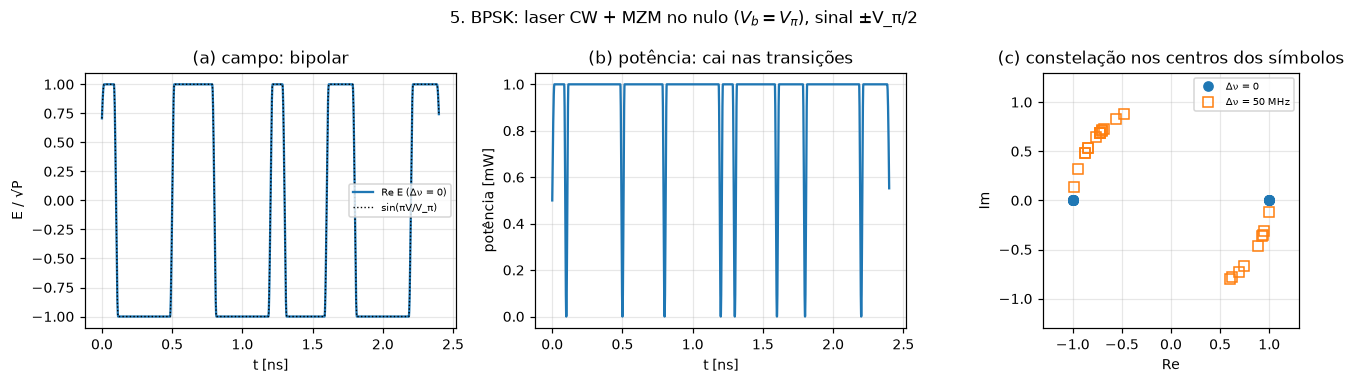

In [6]:
simb5 = 2 * bits4 - 1
x5 = nrz(simb5, SPS)
xe5 = eletrico(x5, SPS)
ctx5 = SimContext(grid=xe5.grid, root_seed=2)
cw0 = CWLaser(CWLaserConfig(power=1e-3, linewidth=0.0), F_LASER)(xe5, ctx5).samples[0]
cw50 = CWLaser(CWLaserConfig(power=1e-3, linewidth=50e6), F_LASER)(xe5, ctx5).samples[0]
t_nulo = pp(VPI / 2 * x5, VPI)
bpsk0 = cw0 * t_nulo * np.exp(-1j * np.angle(cw0[0]))       # tira a fase inicial do laser
bpsk50 = cw50 * t_nulo * np.exp(-1j * np.angle(cw50[0]))
fig, ax = plt.subplots(1, 3, figsize=(12.5, 3.5))
ax[0].plot(t4 * 1e9, bpsk0.real / np.sqrt(1e-3), "-", color=C3[0], label="Re E (Δν = 0)")
ax[0].plot(t4 * 1e9, np.sin(np.pi * x5 / 2), ":", color="k", lw=0.9, label="sin(πV/V_π)")
ax[0].set(xlabel="t [ns]", ylabel="E / √P", title="(a) campo: bipolar")
ax[1].plot(t4 * 1e9, np.abs(bpsk0) ** 2 * 1e3, "-", color=C3[0])
ax[1].set(xlabel="t [ns]", ylabel="potência [mW]", title="(b) potência: cai nas transições")
ax[2].plot(bpsk0[centros].real / np.sqrt(1e-3), bpsk0[centros].imag / np.sqrt(1e-3), "o",
           color=C3[0], label="Δν = 0")
ax[2].plot(bpsk50[centros].real / np.sqrt(1e-3), bpsk50[centros].imag / np.sqrt(1e-3), "s",
           mfc="none", color=C3[1], label="Δν = 50 MHz")
ax[2].set(xlim=(-1.3, 1.3), ylim=(-1.3, 1.3), aspect="equal", xlabel="Re", ylabel="Im",
          title="(c) constelação nos centros dos símbolos")
for a_ in (ax[0], ax[2]): a_.legend(fontsize=6.5)
fig.suptitle("5. BPSK: laser CW + MZM no nulo ($V_b = V_\\pi$), sinal ±V_π/2")
fig.tight_layout()

**Leitura.** (a) O campo segue $\sin(\pi V/V_\pi)$ e troca de sinal a cada troca de símbolo.
(b) A potência é a mesma nos dois símbolos e vai a zero no meio das transições: a informação
está na fase. (c) Sem ruído de fase os símbolos ficam em ±1 no eixo real; com 50 MHz de
largura de linha a constelação gira devagar ao longo dos 24 símbolos. Recuperar essa fase é
o papel do receptor coerente (oscilador local e DSP), passo seguinte da aula.

Testes: issue #15.

## 6. Modulador em quadratura: QPSK e 16QAM

**[Fato: Agrawal, Fig. 10.3]** Com os dois MZ internos no nulo e π/2 entre os braços, QPSK
sai em $(\pm1 \pm i)$, a menos de normalização. **[Dedução]** Para 16QAM, cada braço recebe 4
níveis $\{-3, -1, 1, 3\}\cdot a$; como o campo de cada braço é $\sin(\pi V/V_\pi)$, os pontos
ficam em $\tfrac{1}{2}[\sin(\pi v_I/V_\pi) + i\,\sin(\pi v_Q/V_\pi)]$. Com sinal pequeno a
grade é quadrada e uniforme; com a excursão inteira ($3a = V_\pi/2$) o seno comprime os
pontos externos (razão externo/interno $\sin(\pi/2)/\sin(\pi/6) = 2$ em vez de 3).

**[Fato: VPI]** `PhaseShiftX = -90+5` graus: o VPI usa −90° entre os braços e põe 5° de
desbalanço. O professor usa +90°. O sinal espelha a constelação (dúvida M1).

razão externo/interno em (b): 2.0000 (sem compressão: 3) | em (a): 2.9842
erro máximo kernel × dedução: ['5.9e-17', '1.6e-16', '1.8e-16']
θ = −π/2 (VPI): símbolo (+3, +3) em 0.5000-0.5000j; θ = +π/2 (professor): em 0.5000+0.5000j


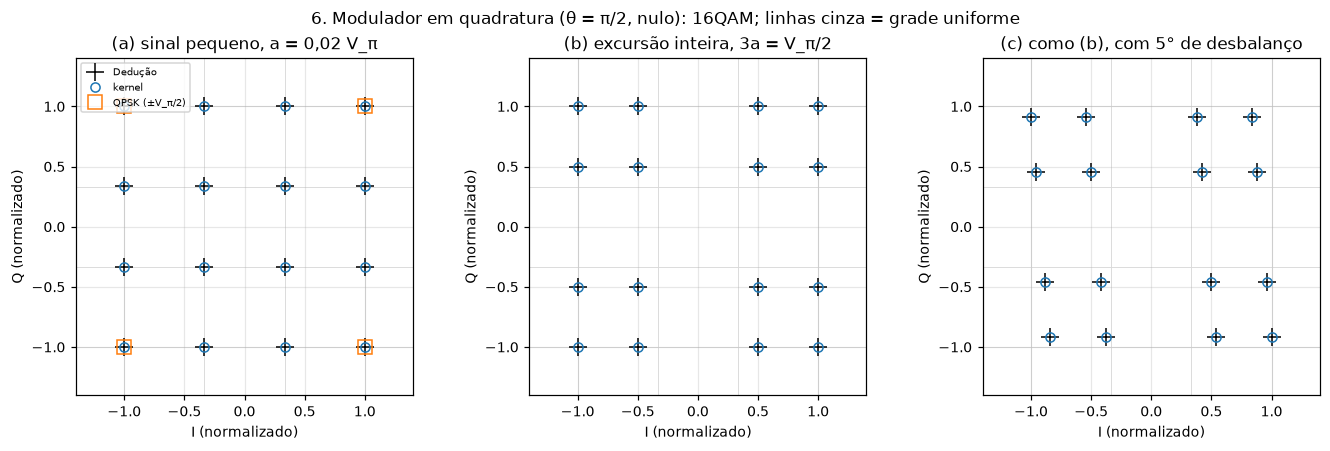

In [7]:
niveis = np.array([-3, -1, 1, 3])
VI, VQ = np.meshgrid(niveis, niveis)
VI, VQ = VI.ravel(), VQ.ravel()
qpsk = iq_field(1.0, np.array([1, -1, -1, 1]) * VPI / 2, np.array([1, 1, -1, -1]) * VPI / 2,
                VPI, VPI, np.pi / 2)
def qam16(a, theta):
    return iq_field(1.0, VI * a, VQ * a, VPI, VPI, theta)
def qam16_ana(a, theta):
    return 0.5 * (np.sin(np.pi * VI * a / VPI) + np.exp(1j * theta) * np.sin(np.pi * VQ * a / VPI))

pequeno, cheio = 0.02 * VPI, VPI / 6
fig, ax = plt.subplots(1, 3, figsize=(12.5, 4.0))
casos6 = [(ax[0], pequeno, np.pi / 2, "(a) sinal pequeno, a = 0,02 V_π"),
          (ax[1], cheio, np.pi / 2, "(b) excursão inteira, 3a = V_π/2"),
          (ax[2], cheio, np.pi / 2 + np.deg2rad(5), "(c) como (b), com 5° de desbalanço")]
erros6 = []
for a_, a, th, titulo in casos6:
    s, ref = qam16(a, th), qam16_ana(a, th)
    escala = np.max(np.abs(s.real))
    a_.plot(ref.real / escala, ref.imag / escala, "+", ms=12, color="k", label="Dedução")
    a_.plot(s.real / escala, s.imag / escala, "o", mfc="none", color=C3[0], label="kernel")
    grade = niveis / 3
    for g in grade:
        a_.axvline(g, color="0.85", lw=0.6, zorder=0); a_.axhline(g, color="0.85", lw=0.6, zorder=0)
    a_.set(xlim=(-1.4, 1.4), ylim=(-1.4, 1.4), aspect="equal", xlabel="I (normalizado)",
           ylabel="Q (normalizado)", title=titulo)
    erros6.append(np.max(np.abs(s - ref)))
ax[0].plot(qpsk.real / np.max(qpsk.real), qpsk.imag / np.max(qpsk.real), "s", ms=9, mfc="none",
           color=C3[1], label="QPSK (±V_π/2)")
ax[0].legend(fontsize=6.5, loc="upper left")
fig.suptitle("6. Modulador em quadratura (θ = π/2, nulo): 16QAM; linhas cinza = grade uniforme")
fig.tight_layout()
s_cheio = qam16(cheio, np.pi / 2)
print(f"razão externo/interno em (b): {np.max(np.abs(s_cheio.real)) / np.min(np.abs(s_cheio.real)):.4f} "
      f"(sem compressão: 3) | em (a): "
      f"{np.max(np.abs(qam16(pequeno, np.pi/2).real)) / np.min(np.abs(qam16(pequeno, np.pi/2).real)):.4f}")
print("erro máximo kernel × dedução:", [f"{e:.1e}" for e in erros6])
print(f"θ = −π/2 (VPI): símbolo (+3, +3) em {qam16(cheio, -np.pi/2)[np.argmax(VI + VQ)]:.4f}; "
      f"θ = +π/2 (professor): em {qam16(cheio, np.pi/2)[np.argmax(VI + VQ)]:.4f}")

**Leitura.**
- (a) Com sinal pequeno a grade é quadrada e uniforme (razão 3,0), mas a potência de saída
  é pequena: é a escolha do código do professor ($K_{mod}$ = 0,1 V com $V_\pi$ = 2,5 V).
- (b) Com a excursão inteira os pontos externos se aproximam dos internos (razão 2): a
  constelação deixa de ser uniforme, o que custa margem de ruído. O `PreDistortion = Yes` do
  VPI provavelmente compensa isso com arco-seno no sinal elétrico (dúvida M6).
- (c) Com 5° de desbalanço o eixo Q tomba e a grade vira um losango: é o impairment do VPI
  (`PhaseShiftX = -90+5`), que o `IQImpairments.phase_imbalance_deg` vai controlar.
- O sinal de θ espelha a constelação em torno do eixo I (saída da célula): com −90°, o
  símbolo (+3, +3) sai no quarto quadrante. Qual sinal usar depende da convenção de frequência
  do projeto (dúvida M1).

Testes: issue #15.

## Próximos passos (guia, seções 6 e 7)

- Responder às dúvidas M1–M9 do guia.
- Blocos `ExternalModulator` (IMDD) e `IQModulator` (coerente, SP e DP) em
  `components/tx/modulator.py`, com a configuração decidida (polarização, escala do sinal,
  extinção, S21, perdas, skew, desbalanço).